# 04 · Evaluate: the chosen model, the slices, the decision, one look at July
**Owner: P3** · Status: `[ ]`

Order is the protocol: (1) ladder on June, (2) choose the buffer on June, (3) **freeze**, (4) July once, (5) slices, (6) interpretation. Do not run section 4 until Gate 2 is signed off by all three.

In [1]:
import sys; sys.path.insert(0, "..")          # repo root, so `import src...` works
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.config import TARGET
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 140)

from src.clean import build_datasets
from src.config import FINAL_FEATURE_SET, FINAL_MODELS
from src.features import add_features
from src.models import make_pipeline, MODELS, MedianBaseline, RateRule
from src.evaluate import (metrics, bootstrap_vs_baseline, slice_table, buffer_for_coverage, coverage,
                          relative_buffer, coverage_rel, lock_test)

D = build_datasets()
train, val, test = D["train"], D["val"], D["test"]
ytr, yva = train[TARGET], val[TARGET]
print("final:", FINAL_FEATURE_SET, FINAL_MODELS)

final: f4_shape ('linear', 'tree')


## 1. The baseline ladder and the models on June (trained on May)

In [2]:
fitted = {
    "1 median (May)": MedianBaseline().fit(train, ytr),
    "2 rate rule (fit on May)": RateRule().fit(train, ytr),
    # "2b rate rule (TLC constants)": RateRule(start=..., per_mile=...).fit(train, ytr),   # fill from the official fares page
    "3 tree depth 2": make_pipeline(MODELS["tree2"](), FINAL_FEATURE_SET).fit(train, ytr),
}
for name in FINAL_MODELS:
    fitted[f"model: {name}"] = make_pipeline(MODELS[name](), FINAL_FEATURE_SET).fit(train, ytr)
pred_val = {k: m.predict(val) for k, m in fitted.items()}
june = pd.DataFrame({k: metrics(yva, p) for k, p in pred_val.items()}).T.drop(columns="n").round(3)
june

,mae,rmse,bias
1 median (May),7.901,12.552,3.419
2 rate rule (fit on May),2.979,4.151,-0.061
3 tree depth 2,3.948,5.425,-0.079
model: linear,2.590,3.672,-0.070
model: tree,2.747,3.920,-0.073


## 2. The decision: how large a buffer for 90% coverage? (chosen on June)
Quote = prediction + buffer, want actual <= quote on 90% of trips. Compare an additive and a multiplicative buffer, and look at what each costs (average over-quote in $).

In [3]:
BEST = f"model: {FINAL_MODELS[0]}"            # TODO: set to the model you carry forward
p = pred_val[BEST]
buf = buffer_for_coverage(yva, p, q=0.90)
k = relative_buffer(yva, p, q=0.90)
print(f"additive buffer  = ${buf:.2f}  -> June coverage {coverage(yva, p, buf):.3f}, mean over-quote ${np.mean(p + buf - yva):.2f}")
print(f"multiplicative k = {k:.3f}  -> June coverage {coverage_rel(yva, p, k):.3f}")
vs = add_features(val)
slice_table(vs, yva, p, "dist_band", buffer=buf)     # does a single buffer deliver 90% in every slice?

additive buffer  = $4.16  -> June coverage 0.900, mean over-quote $4.23
multiplicative k = 1.305  -> June coverage 0.900


,n,mae,rmse,bias,coverage
dist_band,,,,,
0-1,36033,1.958739,2.774148,0.015796,0.932839
1-2,46274,2.367097,3.307103,-0.066937,0.909560
2-5,34785,2.975383,4.099610,-0.125788,0.880092
5-10,11375,3.638628,4.946470,-0.224186,0.854418
10-20,4825,4.165234,5.592550,0.021408,0.815544
20+,167,2.993201,3.982335,0.391055,0.856287


**Discuss:** where does one global buffer fail (long trips, airports, rush hour)? Would slice-specific buffers fix it, and what would they cost in over-quote? Pick the final rule and **write it down before July**.

## 3. FREEZE: model, features, buffer rule. (Gate 3: all three agree.)

## 4. July: scored once
`lock_test()` raises if July was already scored. Do not run this cell until section 3 is done.

In [4]:
lock_test()                                           # one look at July
yte = test[TARGET]
base_te = fitted["1 median (May)"].predict(test)
final_te = fitted[BEST].predict(test)
days = test.tpep_pickup_datetime.dt.date              # resample whole days (trips within a day are correlated)
july = bootstrap_vs_baseline(yte, final_te, base_te, groups=days, n_boot=2000)
display(july.round(3))
print(f"July coverage with June buffer: {coverage(yte, final_te, buf):.3f}  (target 0.90)")

,point,lo,hi
mae_model,2.512,2.426,2.599
mae_baseline,7.716,7.591,7.837
mae_diff,-5.204,-5.350,-5.056
rmse_model,3.390,3.256,3.536
rmse_baseline,12.239,12.023,12.442
rmse_diff,-8.849,-9.078,-8.613


July coverage with June buffer: 0.924  (target 0.90)


## 5. Slices (July, with n): where does it fail?

In [5]:
ts = add_features(test)
ts["hour_band"] = pd.cut(ts.hour, [-1, 5, 9, 15, 19, 23], labels=["night 0-5", "am 6-9", "midday 10-15", "pm 16-19", "eve 20-23"])
for by in ["pickup_borough", "airport_trip", "hour_band", "dist_band"]:
    print(f"--- {by}"); display(slice_table(ts, yte, final_te, by, buffer=buf).round(3))

--- pickup_borough


,n,mae,rmse,bias,coverage
pickup_borough,,,,,
Bronx,53,4.184,5.474,-1.119,0.887
Brooklyn,524,2.773,3.841,-0.256,0.912
EWR,1,9.654,9.654,-9.654,1.000
Manhattan,118684,2.424,3.260,-0.501,0.926
Queens,9096,3.631,4.742,-1.339,0.905
Staten Island,1,2.234,2.234,-2.234,1.000


--- airport_trip


,n,mae,rmse,bias,coverage
airport_trip,,,,,
0,118829,2.429,3.277,-0.499,0.926
1,9530,3.548,4.566,-1.324,0.905


--- hour_band


,n,mae,rmse,bias,coverage
hour_band,,,,,
night 0-5,8599,1.913,2.486,-0.448,0.971
am 6-9,14578,2.175,3.085,-0.240,0.932
midday 10-15,43520,2.914,3.800,-0.848,0.910
pm 16-19,35062,2.662,3.568,-0.586,0.913
eve 20-23,26600,2.034,2.799,-0.265,0.943


--- dist_band


,n,mae,rmse,bias,coverage
dist_band,,,,,
0-1,34506,1.946,2.681,-0.201,0.942
1-2,43944,2.302,3.074,-0.477,0.931
2-5,33685,2.840,3.685,-0.774,0.913
5-10,11228,3.448,4.481,-1.107,0.900
10-20,4795,3.997,5.111,-1.113,0.871
20+,201,2.940,4.067,-0.542,0.910


## 6. Interpretation
### 6a · Linear coefficients as a price list
Fit the distance-only (and distance + airport) linear models on May and compare them with the official TLC fares. Verify the current official rates on the TLC page; do not rely on memory.

In [6]:
for fs in ["f0_distance"]:
    pipe = make_pipeline(MODELS["linear"](), fs).fit(train, ytr)
    lin = pipe.named_steps["model"]
    print(fs, "-> start charge ${:.2f}, per mile ${:.2f}".format(lin.intercept_, lin.coef_[0]))
# TLC official: start $____, per mile $____ (source: <url>, checked <date>)

f0_distance -> start charge $6.67, per mile $3.99


### 6b · The time-charge story: residual vs hour and vs speed proxy
Fares are billed for time in slow traffic; duration is unknown at booking. Show that residuals are positive where traffic is slow.

,n,mae,rmse,bias,coverage
speed_band,,,,,
"(0, 6]",25938,3.238,4.697,2.870,0.729
"(6, 10]",53624,1.785,2.377,-0.628,0.971
"(10, 15]",31866,2.620,3.148,-1.914,0.973
"(15, 25]",13124,3.326,3.865,-2.785,0.982
"(25, 100]",3807,4.097,4.805,-3.970,0.998


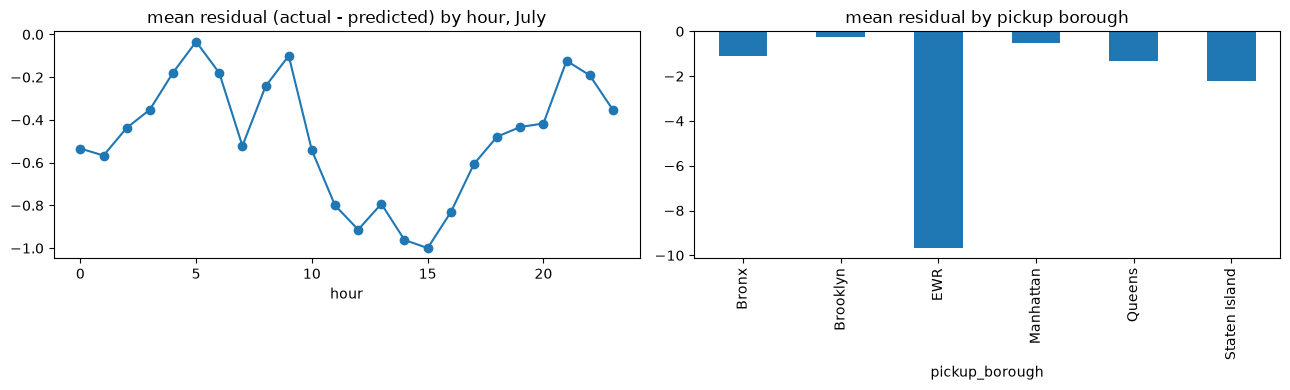

In [7]:
ts["res"] = yte - final_te
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ts.groupby("hour")["res"].mean().plot(ax=ax[0], marker="o", title="mean residual (actual - predicted) by hour, July")
ts.groupby("pickup_borough")["res"].mean().plot(kind="bar", ax=ax[1], title="mean residual by pickup borough")
plt.tight_layout()
# OPTIONAL (analysis only, NOT a feature): implied speed = distance / duration, and mean residual by speed band
dur_h = (test.tpep_dropoff_datetime - test.tpep_pickup_datetime).dt.total_seconds() / 3600
ts["speed_band"] = pd.cut(test.trip_distance / dur_h, [0, 6, 10, 15, 25, 100])
slice_table(ts, yte, final_te, "speed_band", buffer=buf).round(3)

## 7. Fill MODEL_CARD.md from the tables above
Headline numbers, buffer and coverage, failure slices with n, assumptions (planned distance), and what the model must not be used for.